2026-11-16 학습

코드 작성 **Gemini-4-Hydrogen-High**

In [1]:
import platform
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(42)

In [7]:
# OS별 한글 폰트 설정
if platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# 1. MNIST 전체 데이터셋 불러오기 (0~9까지 10개 클래스, 0~255 정수 픽셀)
train_dataset = datasets.MNIST(root="./data", train=True, download=True)
test_dataset = datasets.MNIST(root="./data", train=False, download=True)

# 2. 전처리: 0~255 정수를 255.0으로 나누어 0.0~1.0 실수로 정규화
# 텐서 모양: (데이터 개수, 28스텝[행], 28특성[열])
X_train = train_dataset.data.float() / 255.0
y_train = train_dataset.targets  # 0 ~ 9

X_test = test_dataset.data.float() / 255.0
y_test = test_dataset.targets    # 0 ~ 9

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256, shuffle=False)

In [3]:
# 3. MNIST 10클래스 이미지 분류 RNN 모델 정의
class MNIST10ClassRNN(nn.Module):
    def __init__(self, image_width=28, hidden_dim=64, num_classes=10):
        super().__init__()
        # 10개 숫자의 복잡한 획 조합을 기억하기 위해 은닉 뉴런을 64개로 확장
        self.rnn = nn.RNN(input_size=image_width, hidden_size=hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)  # 10개 클래스 점수 출력

    def forward(self, x):
        outputs, h_n = self.rnn(x)          # outputs: (배치, 28스텝, 64뉴런)
        logits = self.fc(h_n.squeeze(0))    # 마지막 스텝(h_27)으로 0~9 분류
        return logits, outputs


model = MNIST10ClassRNN(image_width=28, hidden_dim=64, num_classes=10)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss()

In [4]:
# 4. 10클래스 모델 학습 및 에폭별 Loss / Accuracy 출력
for epoch in range(6):
    model.train()
    running_loss = 0.0
    train_correct, train_total = 0, 0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        logits, _ = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        # 배치별 손실과 맞힌 개수 누적
        batch_size = batch_x.size(0)
        running_loss += loss.item() * batch_size
        preds = logits.argmax(dim=-1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_size

    epoch_loss = running_loss / train_total
    epoch_acc = train_correct / train_total * 100

    # 매 에폭마다 테스트 데이터(10,000장) 정확도도 함께 확인
    model.eval()
    test_correct, test_total = 0, 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            logits, _ = model(batch_x)
            preds = logits.argmax(dim=-1)
            test_correct += (preds == batch_y).sum().item()
            test_total += batch_y.size(0)

    test_acc = test_correct / test_total * 100
    print(
        f"Epoch [{epoch + 1}/6] | "
        f"Train Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch [1/6] | Train Loss: 0.9885 | Train Acc: 65.38% | Test Acc: 83.96%
Epoch [2/6] | Train Loss: 0.4572 | Train Acc: 86.05% | Test Acc: 88.15%
Epoch [3/6] | Train Loss: 0.3580 | Train Acc: 89.43% | Test Acc: 91.16%
Epoch [4/6] | Train Loss: 0.2945 | Train Acc: 91.35% | Test Acc: 92.85%
Epoch [5/6] | Train Loss: 0.2724 | Train Acc: 92.06% | Test Acc: 93.37%
Epoch [6/6] | Train Loss: 0.2531 | Train Acc: 92.78% | Test Acc: 92.84%


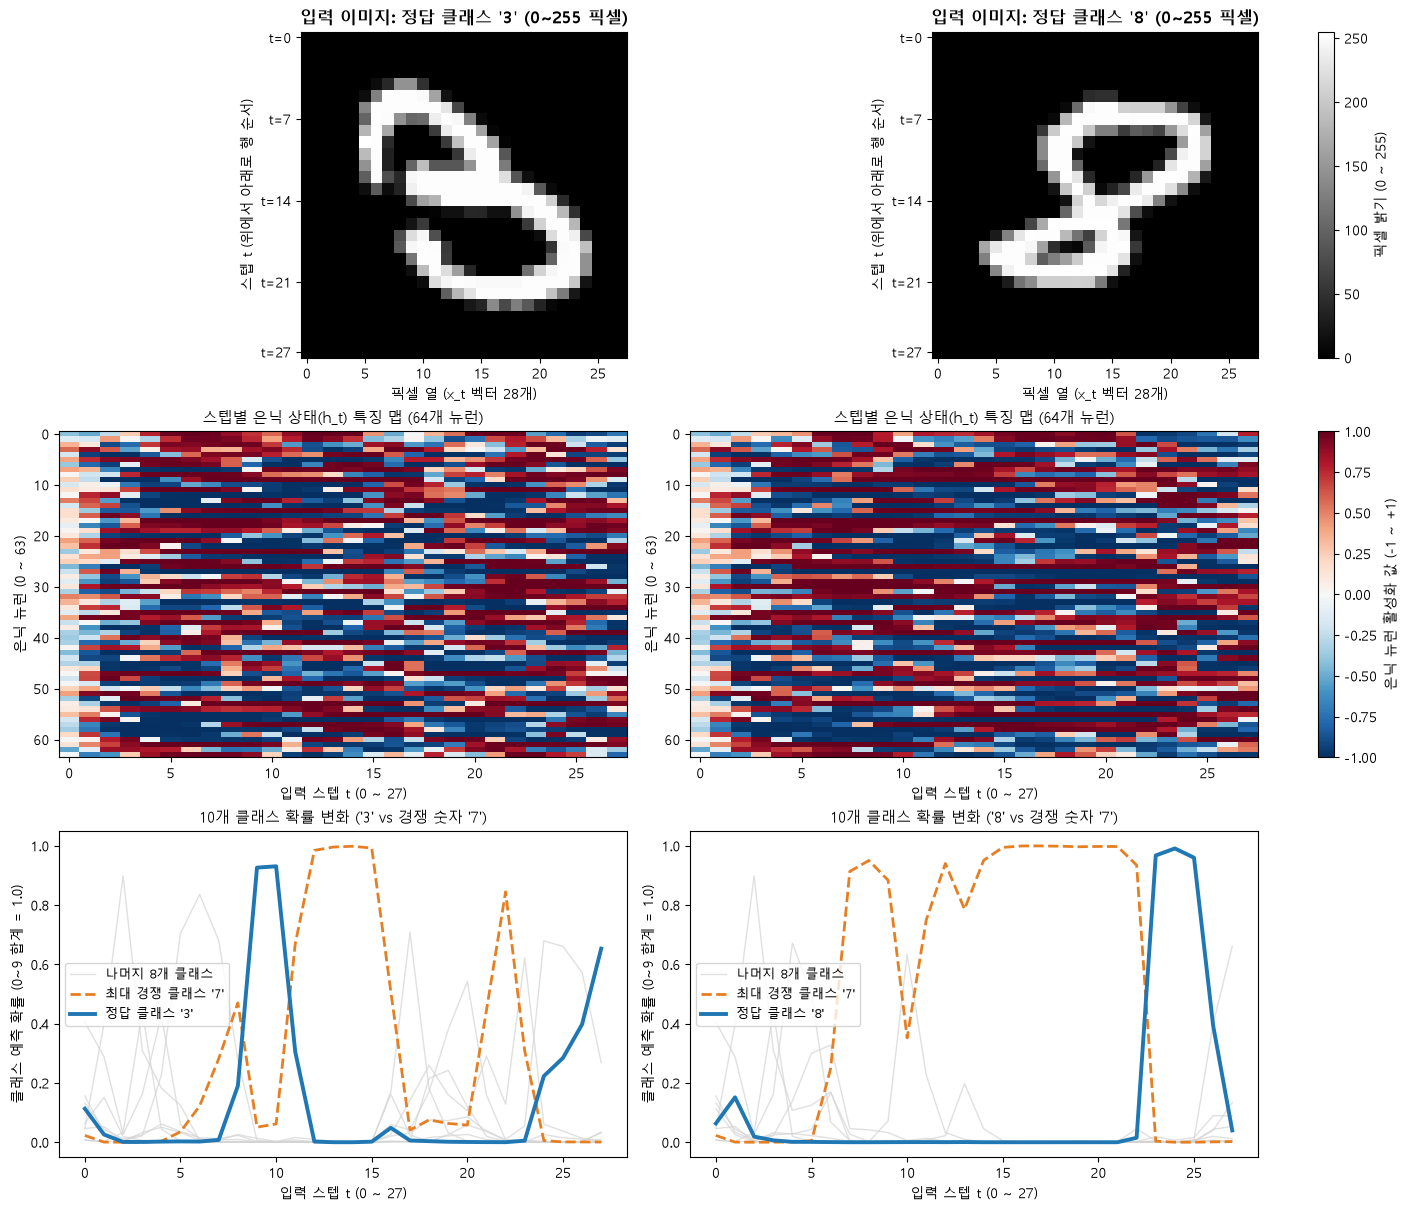

In [8]:
# 5. 테스트 샘플 시각화 (윗부분이 비슷해 중간까지 헷갈리는 숫자 '3'과 '8' 비교)
target_digits = [3, 8]
samples = []
for d in target_digits:
    idx = (y_test == d).nonzero(as_tuple=True)[0][0].item()
    samples.append((test_dataset.data[idx], d))

fig, axes = plt.subplots(3, 2, figsize=(14, 12), constrained_layout=True)


with torch.no_grad():
    for col, (img_255, true_digit) in enumerate(samples):
        x_in = (img_255.float() / 255.0).unsqueeze(0)  # shape: (1, 28, 28)
        _, outputs = model(x_in)                       # shape: (1, 28, 64)

        # [상단] 원본 28x28 (0~255 픽셀) 이미지
        im_img = axes[0, col].imshow(img_255.numpy(), cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(f"입력 이미지: 정답 클래스 '{true_digit}' (0~255 픽셀)", fontsize=12, fontweight="bold")
        axes[0, col].set_ylabel("스텝 t (위에서 아래로 행 순서)")
        axes[0, col].set_xlabel("픽셀 열 (x_t 벡터 28개)")
        axes[0, col].set_yticks([0, 7, 14, 21, 27])
        axes[0, col].set_yticklabels(["t=0", "t=7", "t=14", "t=21", "t=27"])

        # [중단] 64개 은닉 뉴런의 스텝별 활성화 히트맵 (CNN의 Feature Map에 대응)
        hidden_map = outputs.squeeze(0).T.numpy()  # shape: (64, 28)
        im_hid = axes[1, col].imshow(hidden_map, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        axes[1, col].set_title("스텝별 은닉 상태(h_t) 특징 맵 (64개 뉴런)", fontsize=11)
        axes[1, col].set_xlabel("입력 스텝 t (0 ~ 27)")
        axes[1, col].set_ylabel("은닉 뉴런 (0 ~ 63)")

        # [하단] 매 스텝의 h_t를 출력층(fc)에 넣었을 때 0~9 전체 클래스 확률 변화
        step_logits = model.fc(outputs.squeeze(0))  # shape: (28, 10)
        probs = torch.softmax(step_logits, dim=-1).numpy()

        # 정답 외 9개 클래스 중 중간에 가장 강하게 치고 올라온 경쟁 클래스 찾기
        other_digits = [d for d in range(10) if d != true_digit]
        rival_digit = max(other_digits, key=lambda d: probs[:, d].max())

        # 나머지 8개 클래스는 연한 회색 배경선으로 표시
        labeled_others = False
        for d in other_digits:
            if d == rival_digit:
                continue
            axes[2, col].plot(
                range(28), probs[:, d], color="lightgray", linewidth=1.0, alpha=0.7,
                label="나머지 8개 클래스" if not labeled_others else ""
            )
            labeled_others = True

        # 가장 치열했던 경쟁 클래스(점선)와 실제 정답 클래스(굵은 실선) 강조
        axes[2, col].plot(
            range(28), probs[:, rival_digit], linestyle="--", linewidth=2.0, color="#e67e22",
            label=f"최대 경쟁 클래스 '{rival_digit}'"
        )
        axes[2, col].plot(
            range(28), probs[:, true_digit], linewidth=2.8, color="#1f77b4",
            label=f"정답 클래스 '{true_digit}'"
        )

        axes[2, col].set_ylim(-0.05, 1.05)
        axes[2, col].set_xlabel("입력 스텝 t (0 ~ 27)")
        axes[2, col].set_ylabel("클래스 예측 확률 (0~9 합계 = 1.0)")
        axes[2, col].set_title(f"10개 클래스 확률 변화 ('{true_digit}' vs 경쟁 숫자 '{rival_digit}')", fontsize=11)
        axes[2, col].legend(loc="center left", fontsize=9)

fig.colorbar(im_img, ax=axes[0, :], fraction=0.02, label="픽셀 밝기 (0 ~ 255)")
fig.colorbar(im_hid, ax=axes[1, :], fraction=0.02, label="은닉 뉴런 활성화 값 (-1 ~ +1)")
plt.show()

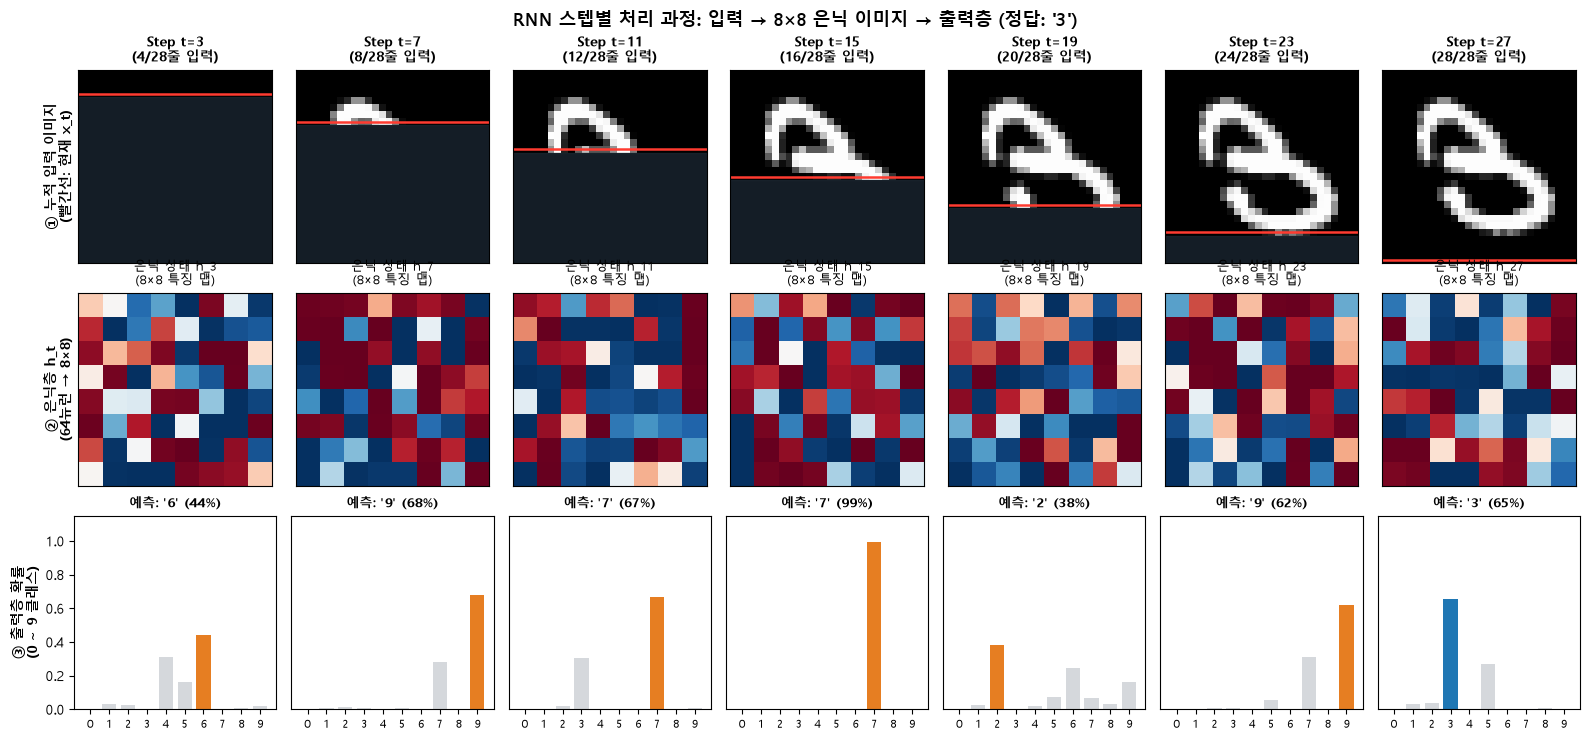

In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 앞서 학습한 model, test_dataset, y_test를 그대로 사용합니다.
target_digit = 3  # 0~9 중 보고 싶은 숫자로 변경 가능
idx = (y_test == target_digit).nonzero(as_tuple=True)[0][0].item()
img_255 = test_dataset.data[idx]

device = next(model.parameters()).device
model.eval()

with torch.no_grad():
    x_in = (img_255.float() / 255.0).unsqueeze(0).to(device)
    _, outputs = model(x_in)  # shape: (1, 28, 64)

    # 매 스텝의 은닉 상태(h_t)와 출력층(0~9 확률) 추출
    hidden_seq = outputs.squeeze(0).cpu().numpy()  # (28, 64)
    step_logits = model.fc(outputs.squeeze(0))     # (28, 10)
    probs = torch.softmax(step_logits, dim=-1).cpu().numpy()  # (28, 10)

# 28스텝 중 흐름이 잘 보이는 7개 스텝 선택
steps = [3, 7, 11, 15, 19, 23, 27]
fig, axes = plt.subplots(3, len(steps), figsize=(16, 7.5))

for col, t in enumerate(steps):
    # ---------------------------------------------------------
    # [1행] 현재 스텝 t까지 RNN이 읽은 입력 이미지 (빨간 선 = 현재 x_t)
    # ---------------------------------------------------------
    seen_img = np.zeros((28, 28), dtype=np.float32)
    seen_img[:t + 1, :] = img_255[:t + 1, :].numpy()  # 0행~t행까지만 공개

    axes[0, col].imshow(seen_img, cmap="gray", vmin=0, vmax=255)
    axes[0, col].axhline(t, color="#ff3b30", linewidth=1.8)  # 현재 읽고 있는 줄 표시
    if t < 27:
        # 아직 읽지 않은 미래 영역은 어두운 푸른빛으로 가림
        axes[0, col].axhspan(t + 0.5, 27.5, color="#1c2833", alpha=0.75)

    axes[0, col].set_title(f"Step t={t}\n({t + 1}/28줄 입력)", fontsize=10, fontweight="bold")
    axes[0, col].set_xticks([])
    axes[0, col].set_yticks([])
    if col == 0:
        axes[0, col].set_ylabel("① 누적 입력 이미지\n(빨간선: 현재 x_t)", fontsize=10, fontweight="bold")

    # ---------------------------------------------------------
    # [2행] 64개 은닉 상태(h_t)를 8x8 이미지(특징 맵)로 변환
    # ---------------------------------------------------------
    h_image = hidden_seq[t].reshape(8, 8)
    axes[1, col].imshow(h_image, cmap="RdBu_r", vmin=-1, vmax=1)
    axes[1, col].set_title(f"은닉 상태 h_{t}\n(8×8 특징 맵)", fontsize=9.5)
    axes[1, col].set_xticks([])
    axes[1, col].set_yticks([])
    if col == 0:
        axes[1, col].set_ylabel("② 은닉층 h_t\n(64뉴런 → 8×8)", fontsize=10, fontweight="bold")

    # ---------------------------------------------------------
    # [3행] 출력층(Linear + Softmax)의 0~9 클래스 예측 확률
    # ---------------------------------------------------------
    p = probs[t]
    pred_digit = int(np.argmax(p))

    # 정답을 맞히면 파란색, 다른 숫자로 착각 중이면 주황색 막대 표시
    bar_colors = ["#d5d8dc"] * 10
    bar_colors[pred_digit] = "#1f77b4" if pred_digit == target_digit else "#e67e22"

    axes[2, col].bar(range(10), p, color=bar_colors, width=0.75)
    axes[2, col].set_ylim(0, 1.15)
    axes[2, col].set_xticks(range(10))
    axes[2, col].tick_params(axis="x", labelsize=8)
    axes[2, col].set_title(f"예측: '{pred_digit}' ({p[pred_digit] * 100:.0f}%)", fontsize=9.5, fontweight="bold")
    if col == 0:
        axes[2, col].set_ylabel("③ 출력층 확률\n(0 ~ 9 클래스)", fontsize=10, fontweight="bold")
    else:
        axes[2, col].set_yticks([])

plt.suptitle(f"RNN 스텝별 처리 과정: 입력 → 8×8 은닉 이미지 → 출력층 (정답: '{target_digit}')", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

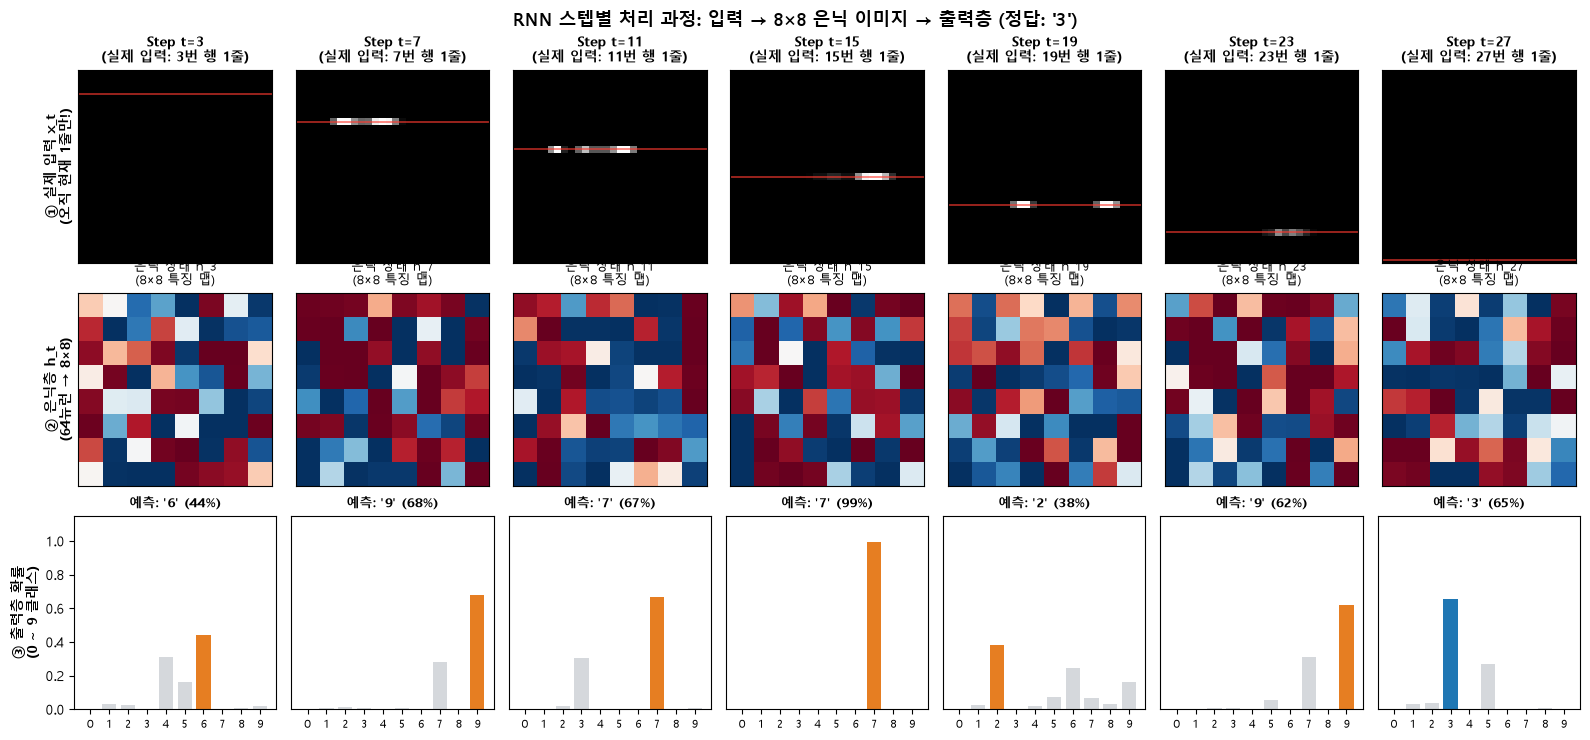

In [11]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 앞서 학습한 model, test_dataset, y_test를 그대로 사용합니다.
target_digit = 3  # 0~9 중 보고 싶은 숫자로 변경 가능
idx = (y_test == target_digit).nonzero(as_tuple=True)[0][0].item()
img_255 = test_dataset.data[idx]

device = next(model.parameters()).device
model.eval()

with torch.no_grad():
    x_in = (img_255.float() / 255.0).unsqueeze(0).to(device)
    _, outputs = model(x_in)  # shape: (1, 28, 64)

    # 매 스텝의 은닉 상태(h_t)와 출력층(0~9 확률) 추출
    hidden_seq = outputs.squeeze(0).cpu().numpy()  # (28, 64)
    step_logits = model.fc(outputs.squeeze(0))     # (28, 10)
    probs = torch.softmax(step_logits, dim=-1).cpu().numpy()  # (28, 10)

# 28스텝 중 흐름이 잘 보이는 7개 스텝 선택
steps = [3, 7, 11, 15, 19, 23, 27]
fig, axes = plt.subplots(3, len(steps), figsize=(16, 7.5))

for col, t in enumerate(steps):
    # ---------------------------------------------------------
    # [1행 수정] 누적 이미지 대신, 현재 스텝 t에 실제로 입력되는 '1줄(x_t)'만 표시
    # ---------------------------------------------------------
    slit_img = np.zeros((28, 28), dtype=np.float32)
    slit_img[t, :] = img_255[t, :].numpy()  # 오직 현재 t번째 한 줄만 복사

    axes[0, col].imshow(slit_img, cmap="gray", vmin=0, vmax=255)
    axes[0, col].axhline(t, color="#ff3b30", linewidth=1.2, alpha=0.7)
    axes[0, col].set_title(f"Step t={t}\n(실제 입력: {t}번 행 1줄)", fontsize=10, fontweight="bold")
    axes[0, col].set_xticks([])
    axes[0, col].set_yticks([])
    if col == 0:
        axes[0, col].set_ylabel("① 실제 입력 x_t\n(오직 현재 1줄만!)", fontsize=10, fontweight="bold")

    # ---------------------------------------------------------
    # [2행] 64개 은닉 상태(h_t)를 8x8 이미지(특징 맵)로 변환
    # ---------------------------------------------------------
    h_image = hidden_seq[t].reshape(8, 8)
    axes[1, col].imshow(h_image, cmap="RdBu_r", vmin=-1, vmax=1)
    axes[1, col].set_title(f"은닉 상태 h_{t}\n(8×8 특징 맵)", fontsize=9.5)
    axes[1, col].set_xticks([])
    axes[1, col].set_yticks([])
    if col == 0:
        axes[1, col].set_ylabel("② 은닉층 h_t\n(64뉴런 → 8×8)", fontsize=10, fontweight="bold")

    # ---------------------------------------------------------
    # [3행] 출력층(Linear + Softmax)의 0~9 클래스 예측 확률
    # ---------------------------------------------------------
    p = probs[t]
    pred_digit = int(np.argmax(p))

    # 정답을 맞히면 파란색, 다른 숫자로 착각 중이면 주황색 막대 표시
    bar_colors = ["#d5d8dc"] * 10
    bar_colors[pred_digit] = "#1f77b4" if pred_digit == target_digit else "#e67e22"

    axes[2, col].bar(range(10), p, color=bar_colors, width=0.75)
    axes[2, col].set_ylim(0, 1.15)
    axes[2, col].set_xticks(range(10))
    axes[2, col].tick_params(axis="x", labelsize=8)
    axes[2, col].set_title(f"예측: '{pred_digit}' ({p[pred_digit] * 100:.0f}%)", fontsize=9.5, fontweight="bold")
    if col == 0:
        axes[2, col].set_ylabel("③ 출력층 확률\n(0 ~ 9 클래스)", fontsize=10, fontweight="bold")
    else:
        axes[2, col].set_yticks([])

plt.suptitle(f"RNN 스텝별 처리 과정: 입력 → 8×8 은닉 이미지 → 출력층 (정답: '{target_digit}')", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()